# C01 - Xuất khẩu, nhập khẩu và cán cân thương mại Việt Nam

- **PIC:** Nguyễn Ngọc Khánh Vân. 
- **Phạm vi:** Việt Nam (`VNM`), 2005–2024; USD danh nghĩa, hiển thị tỷ USD.
- **Dữ liệu:** `data/clean/trade_year.csv`.
- **Thiết kế:** C01A hai đường cùng thang đo; C01B cột âm/dương qua mốc 0.
- **House Style:** import bộ hiện hành từ `notebooks/house_style/house_style.py`.


In [1]:
from pathlib import Path
import sys
import textwrap

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from matplotlib.patches import Patch
from IPython.display import display, Image

ROOT_C01 = next((p for p in (Path.cwd(), *Path.cwd().parents)
                 if (p / "data/clean/trade_year.csv").is_file()
                 and (p / "notebooks/house_style/house_style.py").is_file()), None)
if ROOT_C01 is None:
    raise FileNotFoundError("Mở notebook từ trong repository P03 có data/clean/ và House Style.")
if str(ROOT_C01 / "notebooks") not in sys.path:
    sys.path.insert(0, str(ROOT_C01 / "notebooks"))

from house_style.house_style import (
    apply_style, declutter, format_number, TRADE_FLOW_COLORS,
    TRADE_FLOW_LINESTYLES, TRADE_FLOW_MARKERS, DIVERGING_CMAP,
    diverging_norm, DIRECT_LABEL, SUBTITLE, SOURCE, SLIDE_SIZE, BAR_WIDTH,
)

DATA_C01 = ROOT_C01 / "data/clean/trade_year.csv"
OUT_C01 = ROOT_C01 / "outputs/core_charts/C01"
OUT_C01.mkdir(parents=True, exist_ok=True)
df_c01_raw = pd.read_csv(DATA_C01, dtype={"country_iso3": "string"}, encoding="utf-8-sig")

FORMATS_C01 = ("png", "svg")

def check_c01(condition, message):
    if not bool(condition):
        raise ValueError(message)

def save_c01(fig, code, formats=FORMATS_C01):
    check_c01(set(formats) <= {"png", "svg"}, "Định dạng ảnh không được hỗ trợ.")
    folder_c01 = OUT_C01
    folder_c01.mkdir(parents=True, exist_ok=True)
    paths_c01 = []
    with apply_style():
        for extension_c01 in formats:
            path_c01 = folder_c01 / f"{code}.{extension_c01}"
            fig.savefig(path_c01, dpi=300, bbox_inches="tight", facecolor="white")
            check_c01(path_c01.is_file() and path_c01.stat().st_size > 0, f"Chưa lưu được {path_c01}.")
            paths_c01.append(path_c01)
    return paths_c01

print("Dữ liệu:", DATA_C01.relative_to(ROOT_C01))
print("Số dòng nguồn:", len(df_c01_raw))

def add_value_tables_c01(fig, data, fields, signed=False):
    """Bảng đủ từng năm, tối đa 10 năm/khối để không thu nhỏ chữ."""
    for block_c01, start_c01 in enumerate(range(0, len(data), 10)):
        part_c01 = data.iloc[start_c01:start_c01 + 10]
        bottom_c01 = 0.255 - block_c01 * 0.145
        table_ax_c01 = fig.add_axes([0.09, bottom_c01, 0.87, 0.095])
        table_ax_c01.axis("off")
        labels_c01 = ["Chỉ tiêu"] + [str(int(y)) for y in part_c01.year]
        values_c01 = [[label] + [format_number(v, 1, signed=signed) for v in part_c01[column]]
                      for column, label in fields]
        table_c01 = table_ax_c01.table(
            cellText=values_c01, colLabels=labels_c01, cellLoc="center", loc="center",
            colWidths=[0.15] + [0.85 / len(part_c01)] * len(part_c01), bbox=[0, 0, 1, 1])
        table_c01.auto_set_font_size(False)
        table_c01.set_fontsize(9)
        for (row_c01, col_c01), cell_c01 in table_c01.get_celld().items():
            cell_c01.set_edgecolor("#C6C6C6")
            cell_c01.set_linewidth(0.5)
            if row_c01 == 0:
                cell_c01.set_facecolor("#F2F2F2")
                cell_c01.get_text().set_fontweight("bold")
            if col_c01 == 0:
                cell_c01.get_text().set_fontweight("bold")
        fig.text(0.09, bottom_c01 + 0.105,
                 f"Bảng giá trị (tỷ USD) · {int(part_c01.year.iloc[0])}–{int(part_c01.year.iloc[-1])}",
                 fontsize=9, color="#555555", ha="left")

Dữ liệu: data\clean\trade_year.csv
Số dòng nguồn: 20


## C01A — Xu hướng xuất khẩu và nhập khẩu

- **Câu hỏi phụ Q1.1:** Xuất khẩu và nhập khẩu Việt Nam thay đổi như thế nào trong 2005–2024?
- **Task (action + target):** Xác định xu hướng và so sánh kim ngạch xuất khẩu/nhập khẩu qua thời gian.
- **Dạng:** line chart, hai đường chung một thang đo.
- **Lý do chọn:** trục năm liên tục giúp theo dõi thay đổi và khoảng cách hai chiều; không dùng trục kép.
- **Nguồn/cột:** `data/clean/trade_year.csv` — `year`, `country_iso3`, `export_usd`, `import_usd`.
- **Xử lý:** lọc VNM, kiểm tra đủ 20 năm, khóa duy nhất, kim ngạch hữu hạn/không âm; chia USD cho 1 tỷ.

In [2]:
# [C01A] HÀM XỬ LÝ DỮ LIỆU
def prep_c01a(raw, start_year=2005, end_year=2024, country="VNM"):
    check_c01(isinstance(start_year, int) and isinstance(end_year, int)
              and start_year < end_year, "Cần ít nhất hai năm nguyên theo thứ tự tăng.")
    required_c01a = {"year", "country_iso3", "export_usd", "import_usd"}
    check_c01(required_c01a <= set(raw.columns), f"Thiếu cột: {sorted(required_c01a - set(raw.columns))}")
    data_c01a = raw.copy(deep=True)
    year_c01a = pd.to_numeric(data_c01a["year"], errors="raise")
    check_c01(np.isfinite(year_c01a).all() and year_c01a.mod(1).eq(0).all(), "Năm thiếu hoặc không nguyên.")
    data_c01a["year"] = year_c01a.astype(int)
    data_c01a["country_iso3"] = data_c01a["country_iso3"].astype("string").str.strip()
    data_c01a = data_c01a.loc[
        data_c01a["country_iso3"].eq(country)
        & data_c01a["year"].between(start_year, end_year)
    ].sort_values("year").reset_index(drop=True)
    check_c01(not data_c01a.duplicated(["country_iso3", "year"]).any(), "Trùng khóa quốc gia × năm.")
    expected_c01a = list(range(start_year, end_year + 1))
    check_c01(data_c01a["year"].tolist() == expected_c01a, "Thiếu năm hoặc sai phạm vi sau lọc.")
    for column_c01a in ("export_usd", "import_usd"):
        data_c01a[column_c01a] = pd.to_numeric(data_c01a[column_c01a], errors="raise")
        check_c01(np.isfinite(data_c01a[column_c01a]).all()
                  and data_c01a[column_c01a].ge(0).all(), f"{column_c01a}: thiếu, âm hoặc không hữu hạn.")
    check_c01((data_c01a.loc[0, ["export_usd", "import_usd"]] > 0).all(),
              "Kim ngạch năm đầu phải dương để tính số lần tăng.")
    data_c01a["export_bn"] = data_c01a["export_usd"] / 1e9
    data_c01a["import_bn"] = data_c01a["import_usd"] / 1e9
    return data_c01a

In [3]:
# [C01A] HÀM VẼ — CHÚ GIẢI, NHÃN SỐ, ACTION TITLE VÀ BẢNG GIÁ TRỊ
def plot_c01a(data, figsize=(12, 9)):
    first_c01a, last_c01a = data.iloc[0], data.iloc[-1]
    start_c01a, end_c01a = int(first_c01a.year), int(last_c01a.year)
    export_ratio_c01a = last_c01a.export_usd / first_c01a.export_usd
    import_ratio_c01a = last_c01a.import_usd / first_c01a.import_usd
    title_c01a = (f"Xuất khẩu tăng {format_number(export_ratio_c01a, 1)} lần; "
                  f"nhập khẩu tăng {format_number(import_ratio_c01a, 1)} lần")
    ticks_c01a = sorted({start_c01a, end_c01a,
                        *range(((start_c01a + 4) // 5) * 5, end_c01a + 1, 5)})
    with apply_style():
        fig_c01a = plt.figure(figsize=figsize)
        ax_c01a = fig_c01a.add_axes([0.09, 0.46, 0.87, 0.32])
        for flow_c01a, column_c01a, label_c01a, offset_c01a in (
            ("Export", "export_bn", "Xuất khẩu", 12),
            ("Import", "import_bn", "Nhập khẩu", -17),
        ):
            color_c01a = TRADE_FLOW_COLORS[flow_c01a]
            ax_c01a.plot(data.year, data[column_c01a], color=color_c01a,
                         linestyle=TRADE_FLOW_LINESTYLES[flow_c01a],
                         marker=TRADE_FLOW_MARKERS[flow_c01a], markersize=4,
                         linewidth=2, label=label_c01a)
            for row_c01a in data.loc[data.year.isin(ticks_c01a)].itertuples():
                value_c01a = getattr(row_c01a, column_c01a)
                # Hai giá trị đầu kỳ gần nhau: lệch ngang để không đè nhãn.
                dx_c01a = 5 if row_c01a.year == start_c01a else 0
                ax_c01a.annotate(format_number(value_c01a, 1),
                                 (row_c01a.year, value_c01a),
                                 xytext=(dx_c01a, (28 if flow_c01a == "Export" else 12)
                                         if row_c01a.year == start_c01a else offset_c01a),
                                 textcoords="offset points",
                                 ha="left" if dx_c01a else "center", va="center",
                                 fontsize=9, fontweight="medium", color=color_c01a)
        ax_c01a.set_xlim(start_c01a - 0.4, end_c01a + 0.6)
        high_c01a = max(data.export_bn.max(), data.import_bn.max())
        ax_c01a.set_ylim(0, np.ceil(high_c01a * 1.12 / 100) * 100)
        ax_c01a.set_xticks(ticks_c01a)
        ax_c01a.set_xlabel("Năm")
        ax_c01a.set_ylabel("Kim ngạch (tỷ USD)")
        ax_c01a.yaxis.set_major_formatter(FuncFormatter(lambda v, _: format_number(v, 0)))
        declutter(ax_c01a, "y")
        ax_c01a.legend(loc="lower center", bbox_to_anchor=(0.5, 1.02), ncol=2)
        fig_c01a.suptitle("C01A · Xu hướng xuất khẩu và nhập khẩu", y=0.955, va="center")
        fig_c01a.text(0.5, 0.900, f"Việt Nam · {start_c01a}–{end_c01a}",
                      **(SUBTITLE | {"color": "#A51C30", "va": "center"}))
        fig_c01a.text(0.5, 0.855, title_c01a, fontsize=11, ha="center", va="center", color="#444444")
        add_value_tables_c01(fig_c01a, data,
                             [("export_bn", "Xuất khẩu"), ("import_bn", "Nhập khẩu")])
        fig_c01a.text(0.5, 0.055,
                      "Nhãn trên đường: các mốc năm trên trục X · Bảng: đủ từng năm, làm tròn 1 chữ số",
                      **SOURCE)
        fig_c01a.text(0.5, 0.025,
                      "Nguồn: CEPII BACI HS2002 V202601 · trade_year.csv · USD danh nghĩa", **SOURCE)
    return fig_c01a, ax_c01a, title_c01a

Xuất khẩu tăng 13.5 lần; nhập khẩu tăng 9.5 lần
    year  export_bn  import_bn
0   2005     37.476     39.654
19  2024    505.202    376.826
Kiểm tra đạt: 20 năm; không trùng/thiếu; chung thang tỷ USD.
Đã lưu: ['outputs\\core_charts\\C01\\C01A.png', 'outputs\\core_charts\\C01\\C01A.svg']
<IPython.core.display.Image object>


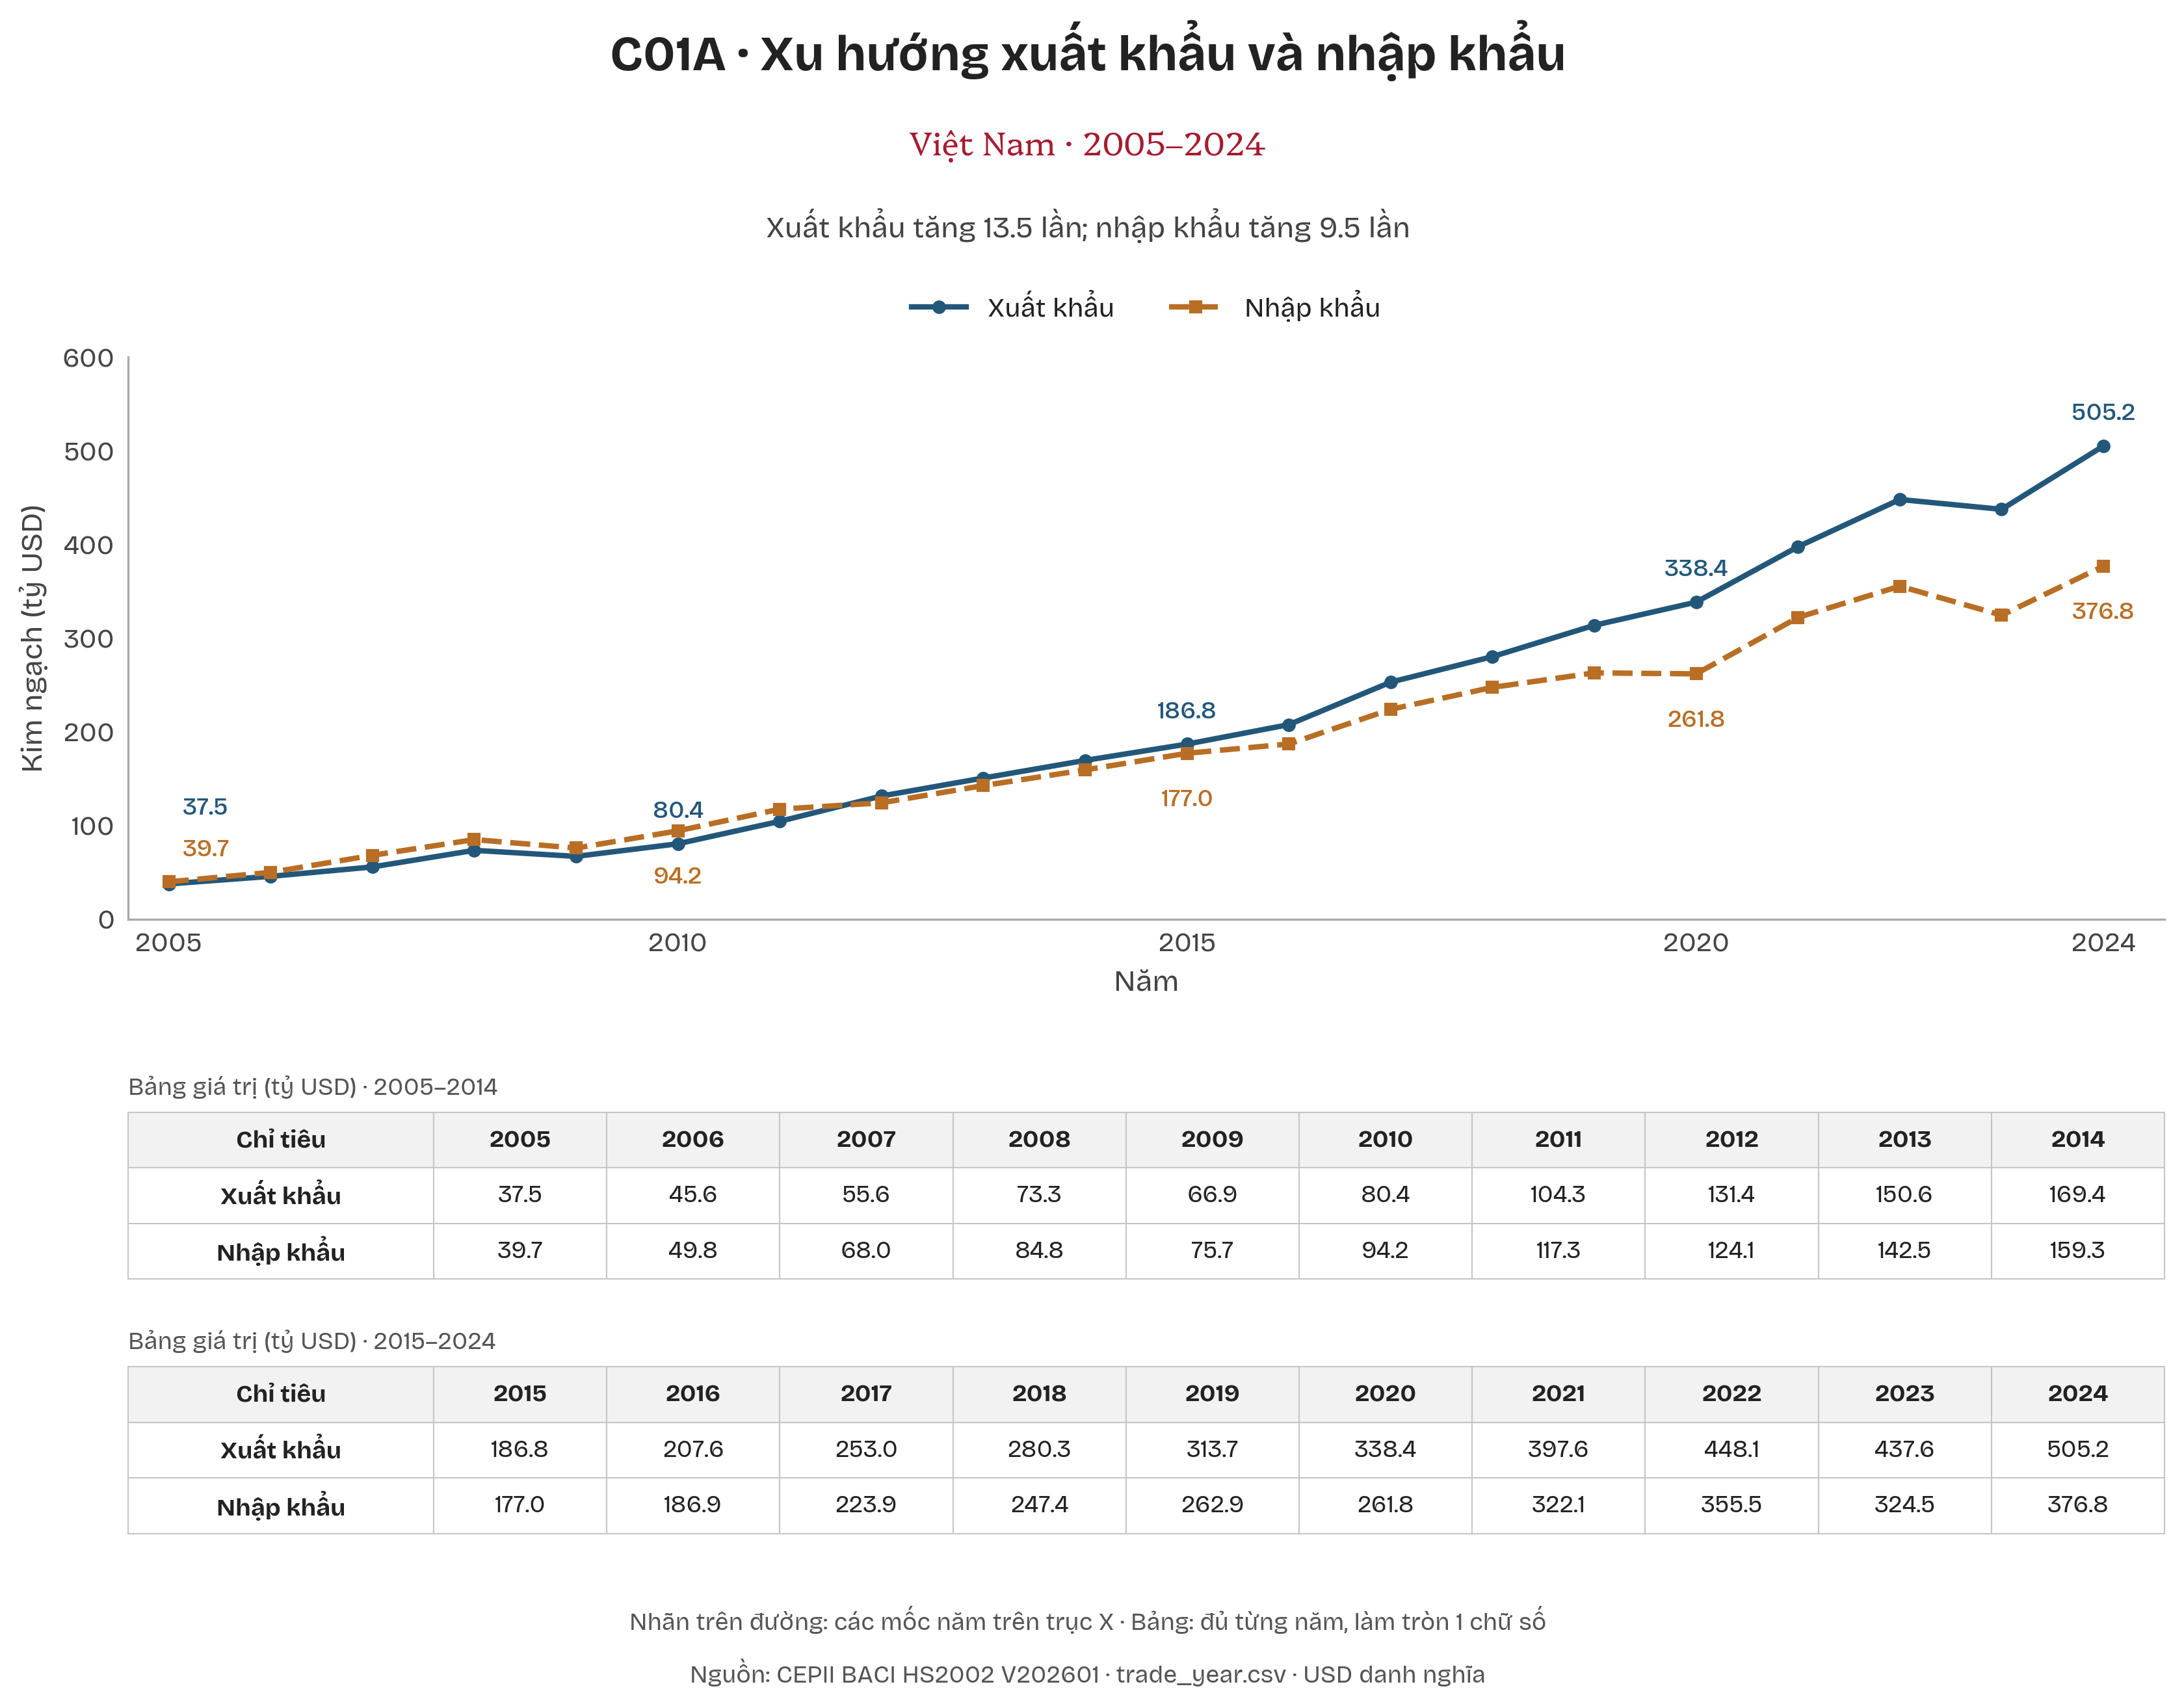

In [4]:
# [C01A] THAM SỐ → GỌI HÀM → KIỂM TRA → LƯU HÌNH
START_YEAR_C01A = 2005
END_YEAR_C01A = 2024
COUNTRY_C01A = "VNM"

df_c01a = prep_c01a(df_c01_raw, START_YEAR_C01A, END_YEAR_C01A, COUNTRY_C01A)
fig_c01a, ax_c01a, title_c01a = plot_c01a(df_c01a)
check_c01(len(df_c01a) == END_YEAR_C01A - START_YEAR_C01A + 1, "Sai số năm C01A.")
check_c01(len(ax_c01a.lines) == 2, "C01A phải có đúng hai đường trên trục biểu đồ.")
check_c01(ax_c01a.get_ylim()[0] == 0, "C01A cần trục Y bắt đầu từ 0.")
files_c01a = save_c01(fig_c01a, "C01A")
print(title_c01a)
display(df_c01a[["year", "export_bn", "import_bn"]].iloc[[0, -1]].round(3))
print("Kiểm tra đạt:", len(df_c01a), "năm; không trùng/thiếu; chung thang tỷ USD.")
print("Đã lưu:", [str(p.relative_to(ROOT_C01)) for p in files_c01a])
plt.close(fig_c01a)
# Hiển thị chính tệp PNG vừa xuất để notebook và output luôn giống nhau.
display(Image(data=(OUT_C01 / "C01A.png").read_bytes(), width=1000))

### Insight, kết luận và hạn chế — C01A
- Xuất khẩu tăng từ **37.476** lên **505.202 tỷ USD**, khoảng **13.48 lần**; nhập khẩu từ **39.654** lên **376.826 tỷ USD**, khoảng **9.50 lần**.
- Cả hai chiều giảm trong 2009 và 2023 so với năm liền trước; xu hướng toàn kỳ không phải tăng liên tục.
- Xuất khẩu vượt nhập khẩu từ 2012 trong chuỗi đang xét. Khoảng cách hai đường là chênh lệch giá trị, được thể hiện trực tiếp ở C01B.
- **Hạn chế:** đây là USD danh nghĩa và số liệu BACI đã hòa giải; không phải tăng trưởng khối lượng thực, không đồng nhất với số Việt Nam tự báo cáo. Biểu đồ tổng quan chưa trả lời cơ cấu theo HS hoặc nguyên nhân biến động.

## C01B — Cán cân thương mại

- **Câu hỏi phụ Q1.1:** Cán cân thương mại Việt Nam biến động ra sao trong 2005–2024?
- **Task (action + target):** So sánh dấu và độ lớn cán cân thương mại giữa các năm.
- **Dạng:** bar chart âm/dương; 20 cột gắn với mốc 0.
- **Lý do chọn:** chiều dài cột và hướng qua 0 thể hiện thặng dư/thâm hụt trực tiếp, không cần suy từ khoảng cách hai đường.
- **Nguồn/cột:** `data/clean/trade_year.csv` — `year`, `country_iso3`, `export_usd`, `import_usd`, `trade_balance_usd`.
- **Xử lý:** tự tính `export_usd − import_usd`, đối chiếu cột cán cân với dung sai tuyệt đối 0.01 USD; sau đó chia 1 tỷ.


- **Màu sắc:** hai màu cố định lấy từ House Style; đỏ có gạch chéo cho thâm hụt, xanh cho thặng dư. Độ cao cột và nhãn số thể hiện mức chênh lệch.


In [5]:
# [C01B] HÀM XỬ LÝ DỮ LIỆU
def prep_c01b(raw, start_year=2005, end_year=2024, country="VNM"):
    check_c01("trade_balance_usd" in raw.columns, "Thiếu trade_balance_usd để đối chiếu.")
    data_c01b = prep_c01a(raw, start_year, end_year, country)
    source_balance_c01b = pd.to_numeric(data_c01b["trade_balance_usd"], errors="raise")
    check_c01(np.isfinite(source_balance_c01b).all(), "Cán cân nguồn thiếu hoặc không hữu hạn.")
    recomputed_c01b = data_c01b["export_usd"] - data_c01b["import_usd"]
    check_c01(np.isclose(recomputed_c01b, source_balance_c01b, rtol=0, atol=0.01).all(),
              "Cán cân không khớp xuất khẩu − nhập khẩu trong dung sai 0.01 USD.")
    data_c01b["balance_difference_usd"] = recomputed_c01b - source_balance_c01b
    data_c01b["balance_bn"] = recomputed_c01b / 1e9
    return data_c01b

In [6]:
# [C01B] HÀM VẼ — CHÚ GIẢI, NHÃN TỪNG CỘT VÀ BẢNG GIÁ TRỊ
def plot_c01b(data, figsize=(12, 9)):
    first_c01b, last_c01b = data.iloc[0], data.iloc[-1]
    start_c01b, end_c01b = int(first_c01b.year), int(last_c01b.year)
    def describe_c01b(value):
        if value == 0:
            return "cân bằng"
        return ("thặng dư " if value > 0 else "thâm hụt ") + format_number(abs(value), 1)
    title_c01b = (f"Từ {describe_c01b(first_c01b.balance_bn)} "
                  f"đến {describe_c01b(last_c01b.balance_bn)} tỷ USD")
    # Hai màu cố định lấy từ bảng màu phân kỳ của House Style.
    deficit_color_c01b = DIVERGING_CMAP(0.15)
    surplus_color_c01b = DIVERGING_CMAP(0.85)
    with apply_style():
        fig_c01b = plt.figure(figsize=figsize)
        ax_c01b = fig_c01b.add_axes([0.09, 0.46, 0.87, 0.32])
        bars_c01b = ax_c01b.bar(data.year, data.balance_bn, width=BAR_WIDTH,
                               color=[deficit_color_c01b if v < 0 else surplus_color_c01b
                                      for v in data.balance_bn],
                               edgecolor="#555555", linewidth=0.65)
        for bar_c01b, row_c01b in zip(bars_c01b, data.itertuples()):
            if row_c01b.balance_bn < 0:
                bar_c01b.set_hatch("///")
            ax_c01b.annotate(format_number(row_c01b.balance_bn, 1, signed=True),
                             (row_c01b.year, row_c01b.balance_bn),
                             xytext=(0, 5 if row_c01b.balance_bn >= 0 else -7),
                             textcoords="offset points", ha="center",
                             va="bottom" if row_c01b.balance_bn >= 0 else "top", fontsize=8)
        ax_c01b.axhline(0, color="#444444", linewidth=1.1, zorder=3)
        bottom_c01b = min(-30.0, float(data.balance_bn.min()) - 20)
        top_c01b = max(10.0, float(data.balance_bn.max()) * 1.2 + 4)
        ax_c01b.set_ylim(bottom_c01b, top_c01b)
        ax_c01b.set_xlim(start_c01b - 0.65, end_c01b + 0.65)
        ax_c01b.set_xticks(sorted({start_c01b, end_c01b,
                                  *range(((start_c01b + 4) // 5) * 5, end_c01b + 1, 5)}))
        ax_c01b.set_xlabel("Năm")
        ax_c01b.set_ylabel("Cán cân (tỷ USD)")
        ax_c01b.yaxis.set_major_formatter(FuncFormatter(lambda v, _: format_number(v, 0)))
        declutter(ax_c01b, "y")
        ticks_y_c01b = {0.0, *(float(t) for t in ax_c01b.get_yticks()
                               if bottom_c01b <= t <= top_c01b)}
        if data.balance_bn.min() < 0:
            ticks_y_c01b.add(float(np.floor(data.balance_bn.min() / 10) * 10))
        ax_c01b.set_yticks(sorted(ticks_y_c01b))
        ax_c01b.set_ylim(bottom_c01b, top_c01b)
        legend_c01b = [
            Patch(facecolor=deficit_color_c01b, edgecolor="#555555", hatch="///",
                  label="Thâm hụt: Nhập khẩu > Xuất khẩu"),
            Patch(facecolor=surplus_color_c01b, edgecolor="#555555",
                  label="Thặng dư: Xuất khẩu > Nhập khẩu"),
        ]
        ax_c01b.legend(handles=legend_c01b, loc="lower center",
                         bbox_to_anchor=(0.5, 1.02), ncol=2, fontsize=9)
        fig_c01b.suptitle("C01B · Cán cân thương mại", y=0.955, va="center")
        fig_c01b.text(0.5, 0.900, f"Việt Nam · {start_c01b}–{end_c01b}",
                      **(SUBTITLE | {"color": "#A51C30", "va": "center"}))
        fig_c01b.text(0.5, 0.855, title_c01b, fontsize=11, ha="center", va="center", color="#444444")
        add_value_tables_c01(fig_c01b, data, [("balance_bn", "Cán cân")], signed=True)
        fig_c01b.text(0.5, 0.065,
                      "Cán cân = Xuất khẩu − Nhập khẩu (tỷ USD). Cột dưới 0: thâm hụt; cột trên 0: thặng dư.",
                      **SOURCE)
        fig_c01b.text(0.5, 0.025,
                      "Nguồn: CEPII BACI HS2002 V202601 · trade_year.csv · USD danh nghĩa", **SOURCE)
    return fig_c01b, ax_c01b, title_c01b

Từ thâm hụt 2.2 đến thặng dư 128.4 tỷ USD
Số năm thâm hụt: 7 | thặng dư: 13
Lệch cán cân tối đa so với cột nguồn: 0.0 USD
    year  balance_bn
0   2005      -2.178
1   2006      -4.246
2   2007     -12.407
3   2008     -11.479
4   2009      -8.873
5   2010     -13.822
6   2011     -12.990
7   2012       7.256
8   2013       8.073
9   2014      10.156
10  2015       9.809
11  2016      20.671
12  2017      29.031
13  2018      32.842
14  2019      50.835
15  2020      76.602
16  2021      75.565
17  2022      92.614
18  2023     113.079
19  2024     128.376
Đã lưu: ['outputs\\core_charts\\C01\\C01B.png', 'outputs\\core_charts\\C01\\C01B.svg']
<IPython.core.display.Image object>


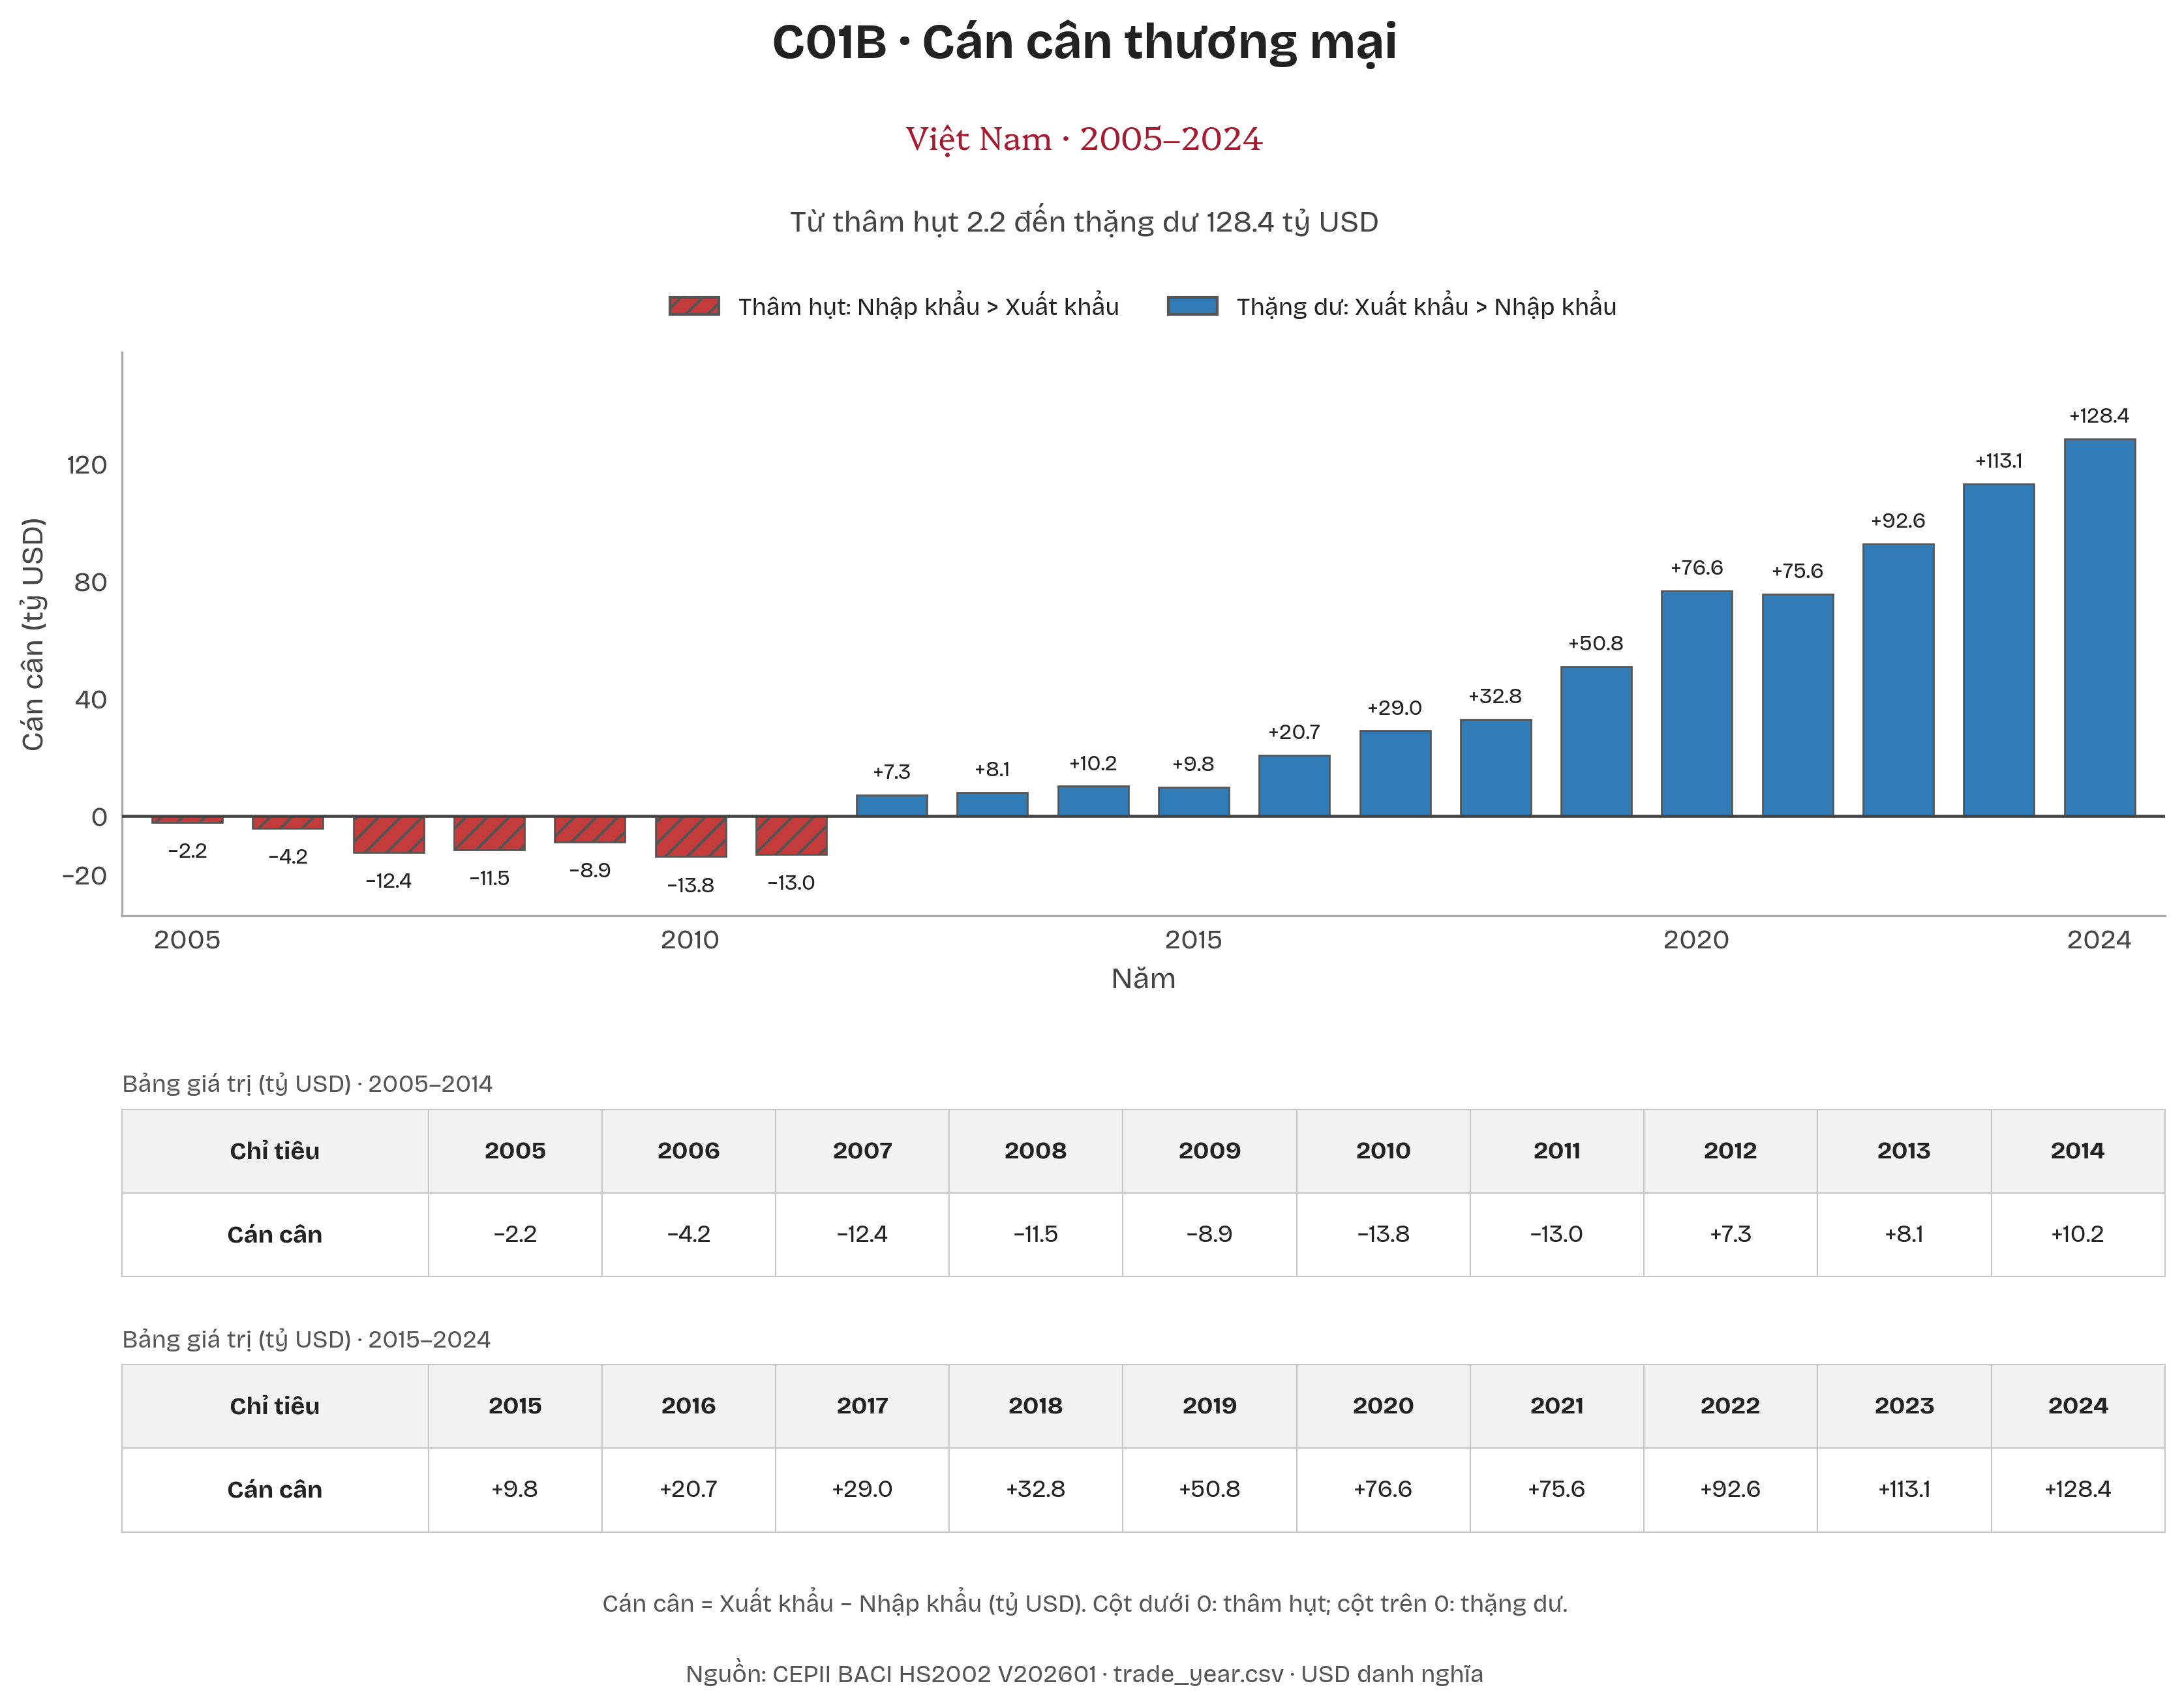

In [7]:
# [C01B] THAM SỐ → GỌI HÀM → KIỂM TRA → LƯU HÌNH
START_YEAR_C01B = 2005
END_YEAR_C01B = 2024
COUNTRY_C01B = "VNM"

df_c01b = prep_c01b(df_c01_raw, START_YEAR_C01B, END_YEAR_C01B, COUNTRY_C01B)
fig_c01b, ax_c01b, title_c01b = plot_c01b(df_c01b)
check_c01(len(ax_c01b.patches) == len(df_c01b), "C01B thiếu hoặc thừa cột.")
check_c01(ax_c01b.get_ylim()[0] < 0 < ax_c01b.get_ylim()[1], "C01B cần thể hiện mốc 0.")
np.testing.assert_allclose([bar.get_height() for bar in ax_c01b.patches], df_c01b.balance_bn, rtol=0, atol=1e-10)
files_c01b = save_c01(fig_c01b, "C01B")
print(title_c01b)
print("Số năm thâm hụt:", int(df_c01b.balance_bn.lt(0).sum()),
      "| thặng dư:", int(df_c01b.balance_bn.gt(0).sum()))
print("Lệch cán cân tối đa so với cột nguồn:", df_c01b.balance_difference_usd.abs().max(), "USD")
display(df_c01b[["year", "balance_bn"]].round(3))
print("Đã lưu:", [str(p.relative_to(ROOT_C01)) for p in files_c01b])
plt.close(fig_c01b)
# Hiển thị chính tệp PNG vừa xuất để notebook và output luôn giống nhau.
display(Image(data=(OUT_C01 / "C01B.png").read_bytes(), width=1000))

### Insight, kết luận và hạn chế — C01B
- Cán cân từ **−2.178 tỷ USD năm 2005** sang **+128.376 tỷ USD năm 2024**.
- Có **7 năm thâm hụt (2005–2011)** và **13 năm thặng dư (2012–2024)** trong dữ liệu đang xét.
- Thâm hụt lớn nhất toàn kỳ ở **2010, khoảng −13.822 tỷ USD**. Thặng dư lớn nhất ở **2024, khoảng +128.376 tỷ USD**.
- Mức thặng dư không tăng đều từng năm: 2015 và 2021 giảm so với năm liền trước. Dương không tự động đồng nghĩa với hiệu quả kinh tế cao hơn.
- **Hạn chế:** cán cân hàng hóa danh nghĩa theo BACI, không phải cán cân dịch vụ/tài khoản vãng lai. 